In [63]:
%pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve)

In [65]:
import pandas as pd
# 1. Les noms des colonnes
columns = [    "age", "workclass", "fnlwgt", "education",    "education-num", "marital-status", "occupation",    "relationship", "race", "sex", "capital-gain",    "capital-loss", "hours-per-week", "native-country",    "income"]
# 2. Charger le dataset
df = pd.read_csv(r"D:\projet ffd\data-mining-adult-income\data\adult.data",header=None,names=columns,skipinitialspace=True)
# 3. Afficher les informations
print("Dimensions :", df.shape)
print("Valeurs de income :", df["income"].unique())
# 4. Afficher les premières lignes
print(df.head())

Dimensions : (32561, 15)
Valeurs de income : ['<=50K' '>50K']
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  Uni

In [66]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
#1. Séparer X et y
y = (df["income"].astype(str).str.strip() == ">50K").astype(int)
X = df.drop(columns=["income"]).copy()
#2. Encoder les variables catégorielles
categorical_cols = [ "workclass", "education", "marital-status", "occupation", "relationship", "race", "sex", "native-country" ]
for col in categorical_cols:
     X[col] = LabelEncoder().fit_transform(X[col].astype(str))
#3. Diviser les données
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )
#4. Normaliser les données
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) 
X_test = scaler.transform(X_test)
#5. Afficher les dimensions
print("Dimensions train :", X_train.shape) 
print("Dimensions test :", X_test.shape)

Dimensions train : (26048, 14)
Dimensions test : (6513, 14)


from sklearn.svm import SVC import numpy as np
1. Prendre un échantillon de 6000 lignes
idx = np.random.RandomState(42).choice( len(X_train), size=6000, replace=False )
2. Extraire les données
Xs = X_train[idx]
if hasattr(y_train, "iloc"): ys = y_train.iloc[idx] else: ys = y_train[idx]
3. Définir la grille des paramètres RBF
grille = { "C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1], "kernel": ["rbf"] }
4. Recherche des meilleurs paramètres SVM RBF
gs_rbf, tab_rbf = grid_search_cv( SVC(class_weight="balanced"), grille, Xs, ys, nom="SVM RBF" )
5. Recherche des meilleurs paramètres SVM linéaire
gs_lin, tab_lin = grid_search_cv( SVC(kernel="linear", class_weight="balanced"), {"C": [0.01, 0.1, 1, 10]}, Xs, ys, nom="SVM linéaire" )
6. Afficher les résultats
display(tab_rbf) display(tab_lin)

In [67]:
def evaluer(nom, model, X_te, y_te):
    y_pred = model.predict(X_te)
    score = model.decision_function(X_te)
    return {"modele": nom,
            "accuracy": accuracy_score(y_te, y_pred),
            "precision": precision_score(y_te, y_pred),
            "recall": recall_score(y_te, y_pred),
            "f1": f1_score(y_te, y_pred),
            "auc": roc_auc_score(y_te, score)}

In [68]:
from sklearn.svm import SVC

resultats = []
svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(X_train, y_train)
resultats.append(evaluer("SVM sans correction", svm, X_test, y_test))

svm_w = SVC(kernel="rbf", class_weight="balanced", random_state=42).fit(X_train, y_train)
resultats.append(evaluer("SVM pondération", svm_w, X_test, y_test))

In [69]:
from imblearn.over_sampling import SMOTE

X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
svm_s = SVC(kernel="rbf", random_state=42).fit(X_sm, y_sm)
resultats.append(evaluer("SVM + SMOTE", svm_s, X_test, y_test))

tableau = pd.DataFrame(resultats).round(4)
tableau

,modele,accuracy,precision,recall,f1,auc
0,SVM sans correction,0.8520,0.7660,0.5563,0.6445,0.8984
1,SVM pondération,0.7993,0.5531,0.8752,0.6778,0.9041
2,SVM + SMOTE,0.8042,0.5611,0.8651,0.6807,0.9022


In [70]:
res_k = []
for k in ["linear", "poly", "rbf"]:
    m = SVC(kernel=k, class_weight="balanced", random_state=42).fit(X_train, y_train)
    res_k.append(evaluer(f"SVM {k}", m, X_test, y_test))
pd.DataFrame(res_k).round(4)

,modele,accuracy,precision,recall,f1,auc
0,SVM linear,0.7640,0.5070,0.7880,0.6170,0.8564
1,SVM poly,0.7929,0.5467,0.8275,0.6584,0.8841
2,SVM rbf,0.7993,0.5531,0.8752,0.6778,0.9041


In [71]:
modeles = {"SVM sans correction": svm, "SVM pondération": svm_w, "SVM + SMOTE": svm_s}
f1s = {n: f1_score(y_test, m.predict(X_test)) for n, m in modeles.items()}
nom_final = max(f1s, key=f1s.get)
modele_final = modeles[nom_final]
print(f1s, "->", nom_final)

{'SVM sans correction': 0.644542772861357, 'SVM pondération': 0.6778407690411634, 'SVM + SMOTE': 0.6806912096168295} -> SVM + SMOTE


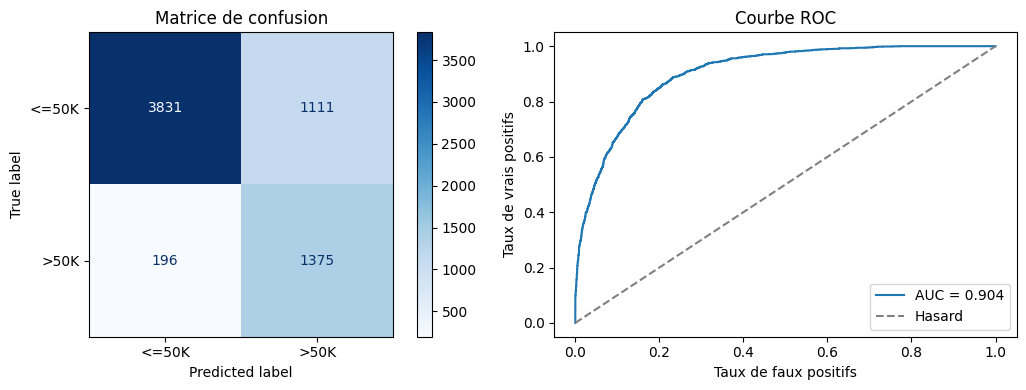

In [72]:
modele_final = svm_w   # khtar el a7sen F1 mel tableau
y_pred = modele_final.predict(X_test)
y_score = modele_final.decision_function(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["<=50K", ">50K"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matrice de confusion")
fpr, tpr, _ = roc_curve(y_test, y_score)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_score):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC"); axes[1].legend()
plt.tight_layout(); plt.show()

In [73]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def grid_search_cv(modele, grille, X_tr, y_tr, scoring="f1", nom="modele"): 
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    gs = GridSearchCV(
    estimator=modele,
    param_grid=grille,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

    gs.fit(X_tr, y_tr)
    res = pd.DataFrame(gs.cv_results_)
    tableau = res[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score").round(4)
    print(f"{nom} - meilleurs paramètres : {gs.best_params_}")
    print(f"Meilleur score {scoring} : {gs.best_score_:.4f}")
    return gs, tableau

In [74]:
from sklearn.svm import SVC
import numpy as np
#1. Prendre un échantillon de 6000 lignes
idx = np.random.RandomState(42).choice( len(X_train), size=6000, replace=False )
#2. Extraire les données
Xs = X_train[idx]
if hasattr(y_train, "iloc"):
     ys = y_train.iloc[idx] 
else:    
     ys = y_train[idx]
#3. Définir la grille des paramètres RBF
grille = { "C": [1, 10, 100], "gamma": ["scale", 0.01, 0.1], "kernel": ["rbf"] }
#4. Recherche des meilleurs paramètres SVM RBF
gs_rbf, tab_rbf = grid_search_cv( SVC(class_weight="balanced"), grille, Xs, ys, nom="SVM RBF" )
#5. Recherche des meilleurs paramètres SVM linéaire
gs_lin, tab_lin = grid_search_cv( SVC(kernel="linear", class_weight="balanced"), {"C": [0.01, 0.1, 1, 10]}, Xs, ys, nom="SVM linéaire" )
#6. Afficher les résultats
display(tab_rbf) 
display(tab_lin)

SVM RBF - meilleurs paramètres : {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Meilleur score f1 : 0.6408
SVM linéaire - meilleurs paramètres : {'C': 1}
Meilleur score f1 : 0.6103


,params,mean_test_score,std_test_score,rank_test_score
4,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.6408,0.0063,1
7,"{'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}",0.6399,0.0038,2
0,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.6391,0.0106,3
1,"{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}",0.6391,0.0116,4
2,"{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}",0.6354,0.0088,5
3,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.6290,0.0099,6
5,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.6199,0.0096,7
6,"{'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}",0.5966,0.0125,8
8,"{'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}",0.5903,0.0179,9


,params,mean_test_score,std_test_score,rank_test_score
2,{'C': 1},0.6103,0.0184,1
3,{'C': 10},0.6102,0.0186,2
1,{'C': 0.1},0.6079,0.0180,3
0,{'C': 0.01},0.6022,0.0171,4


In [75]:
pd.set_option("display.max_colwidth", None)

resume = pd.DataFrame([
    {"modèle": "SVM RBF",
     "paramètres testés": str(gs_rbf.param_grid),
     "meilleurs paramètres": str(gs_rbf.best_params_),
     "F1 CV (5 plis)": round(gs_rbf.best_score_, 4)},
    {"modèle": "SVM linéaire",
     "paramètres testés": str(gs_lin.param_grid),
     "meilleurs paramètres": str(gs_lin.best_params_),
     "F1 CV (5 plis)": round(gs_lin.best_score_, 4)},
])
display(resume)

,modèle,paramètres testés,meilleurs paramètres,F1 CV (5 plis)
0,SVM RBF,"{'C': [1, 10, 100], 'gamma': ['scale', 0.01, 0.1], 'kernel': ['rbf']}","{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.6408
1,SVM linéaire,"{'C': [0.01, 0.1, 1, 10]}",{'C': 1},0.6103


Partie 2 : fonction de grid search réutilisable
La fonction grid_search_cv(modele, grille, X_tr, y_tr, scoring="f1", nom="modele") :
teste toutes les combinaisons de la grille de paramètres ;
évalue chacune par validation croisée stratifiée à 5 plis (StratifiedKFold) ;
utilise le F1 comme score, adapté aux classes déséquilibrées ;
retourne l'objet gs et un tableau trié (paramètres, score moyen, écart-type, rang).
Les autres membres du groupe peuvent l'utiliser pour régler leurs propres algorithmes en changeant seulement modele et grille.
Résultats : SVM RBF, meilleurs paramètres C = 10 et gamma = 0.01 (F1 CV = 0.6408). SVM linéaire, meilleur paramètre C = 1 (F1 CV = 0.6103).
Remarque : la recherche est faite sur un échantillon de 6000 lignes pour réduire le temps de calcul. Le modèle final est ensuite réentraîné sur tout X_train.

In [76]:
meilleur = gs_rbf.best_estimator_.fit(X_train, y_train)
resultat_final = evaluer("SVM RBF (meilleur C, gamma)", meilleur, X_test, y_test)
pd.DataFrame([resultat_final]).round(4)


,modele,accuracy,precision,recall,f1,auc
0,"SVM RBF (meilleur C, gamma)",0.7975,0.5505,0.874,0.6755,0.9054


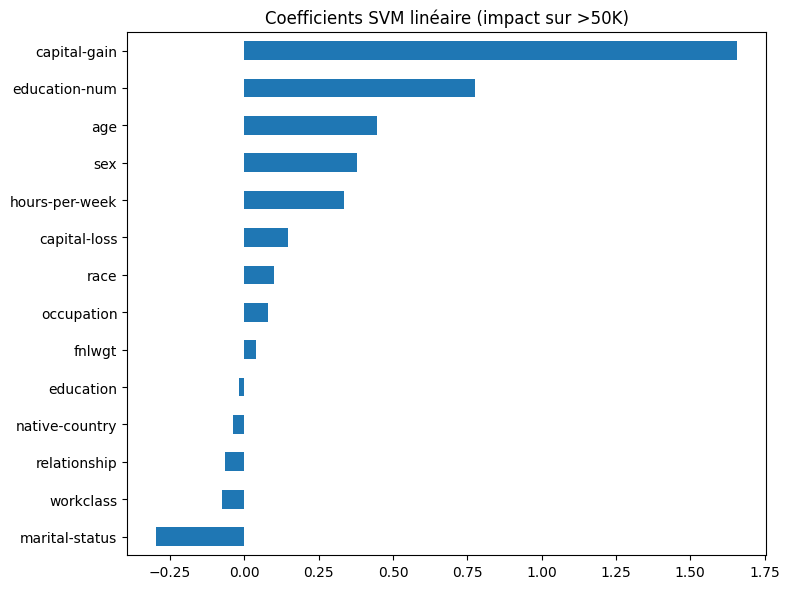

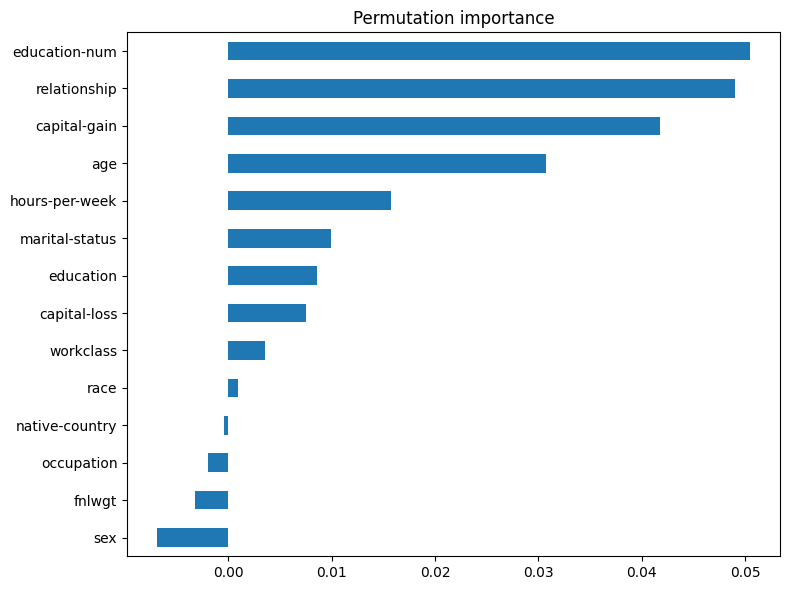

In [77]:
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# 1. Coefficients du SVM linéaire
# =====================================

lin = SVC(
    kernel="linear",
    C=gs_lin.best_params_["C"],
    class_weight="balanced"
).fit(Xs, ys)

coef = pd.Series(
    lin.coef_[0],
    index=X.columns
).sort_values()

coef.plot(
    kind="barh",
    figsize=(8, 6),
    title="Coefficients SVM linéaire (impact sur >50K)"
)

plt.tight_layout()
plt.show()


# =====================================
# 2. Permutation importance (SVM RBF)
# =====================================

# Sélectionner 1500 indices aléatoires
indices = np.random.RandomState(42).choice(
    len(X_test),
    size=min(1500, len(X_test)),
    replace=False
)

# Extraire les données de test
ech = X_test[indices]

# Extraire les étiquettes correspondantes
y_ech = y_test.iloc[indices]

# Calculer l'importance des variables
pi = permutation_importance(
    meilleur,
    ech,
    y_ech,
    n_repeats=5,
    random_state=42,
    scoring="f1"
)

# Créer et trier les importances
importance = pd.Series(
    pi.importances_mean,
    index=X.columns
).sort_values()

# Afficher le graphique
importance.plot(
    kind="barh",
    figsize=(8, 6),
    title="Permutation importance"
)

plt.tight_layout()
plt.show()

In [78]:
print("Top 5 coefficients positifs (favorisent >50K) :")
print(coef.sort_values(ascending=False).head(5))
print("\nTop 5 coefficients négatifs :")
print(coef.sort_values().head(5))
print("\nTop 5 permutation importance :")
print(importance.sort_values(ascending=False).head(5))

Top 5 coefficients positifs (favorisent >50K) :
capital-gain      1.656908
education-num     0.777484
age               0.447655
sex               0.378607
hours-per-week    0.336426
dtype: float64

Top 5 coefficients négatifs :
marital-status   -0.296533
workclass        -0.075744
relationship     -0.063950
native-country   -0.039451
education        -0.017821
dtype: float64

Top 5 permutation importance :
education-num     0.050494
relationship      0.049038
capital-gain      0.041772
age               0.030685
hours-per-week    0.015718
dtype: float64


Interprétation
D'après les coefficients du SVM linéaire et la permutation importance, les facteurs qui influencent le plus le revenu (>50K) sont : [variable 1], [variable 2], [variable 3].
Effet positif : [ex. capital-gain, education-num, age]
Effet négatif : [ex. relationship, marital-status selon l'encodage]
Les deux méthodes [concordent / divergent] sur [...].
Limite : LabelEncoder impose un ordre artificiel aux variables catégorielles, donc l'interprétation des coefficients de ces variables est à prendre avec prudence.